# Unsupervised Learning with scikit-learn
**Intro to ML & AI**

1. Distances and nearest neighbours
2. K-means and choosing k
3. Can we trust the scores?
4. The full workflow on real data (wine)

Run the cells from top to bottom. There are two 🧪 *Try it* exercises.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances, silhouette_score

## 1. Distances and nearest neighbours
Word counts `["match", "goal"]` in three texts. Which text is most like the query?
`pairwise_distances` with `metric="cosine"` gives the cosine **distance** (0 = same direction).

In [2]:
texts = np.array([[1, 2],    # query
                  [2, 4],    # A: long article, same topic
                  [2, 1]])   # B: short text, other mix

for metric in ["euclidean", "manhattan", "cosine"]:
    d = pairwise_distances(texts[:1], texts[1:], metric=metric)[0]
    print(f"{metric:10s} A: {d[0]:.2f}   B: {d[1]:.2f}   nearest: {'AB'[d.argmin()]}")

euclidean  A: 2.24   B: 1.41   nearest: B
manhattan  A: 3.00   B: 2.00   nearest: B
cosine     A: 0.00   B: 0.20   nearest: A


Nearest neighbours: find the 3 wines most similar to wine 0. We scale first, because the features have very different units.

In [3]:
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)   # 178 wines, 13 measurements
X_wine_s = StandardScaler().fit_transform(X_wine)

nn = NearestNeighbors(n_neighbors=4).fit(X_wine_s)    # the wine itself + 3 neighbours
dist, idx = nn.kneighbors(X_wine_s[:1])
print("most similar wines to wine 0:", idx[0][1:], " distances:", dist[0][1:].round(2))

most similar wines to wine 0: [20 56 40]  distances: [1.29 1.56 1.88]


## 2. K-means and choosing k
Toy data where we know there are 4 groups. We try k = 2 … 8 and compute two scores:
- **inertia**: always falls when k grows, so look for the **elbow** (the bend)
- **silhouette**: higher is better (max 1), look for the **peak**

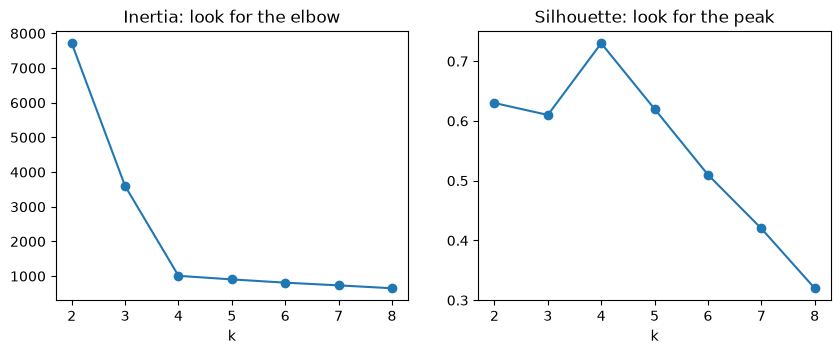

,inertia,silhouette
k,,
2,7716,0.63
3,3597,0.61
4,1008,0.73
5,905,0.62
6,811,0.51
7,733,0.42
8,650,0.32


In [4]:
X, _ = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=3)

def scores_for_k(X, ks=range(2, 9)):
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
        rows.append({"k": k, "inertia": round(km.inertia_), "silhouette": round(silhouette_score(X, km.labels_), 2)})
    return pd.DataFrame(rows).set_index("k")

scores = scores_for_k(X)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
scores["inertia"].plot(ax=axes[0], marker="o", title="Inertia: look for the elbow")
scores["silhouette"].plot(ax=axes[1], marker="o", title="Silhouette: look for the peak")
plt.show()
scores

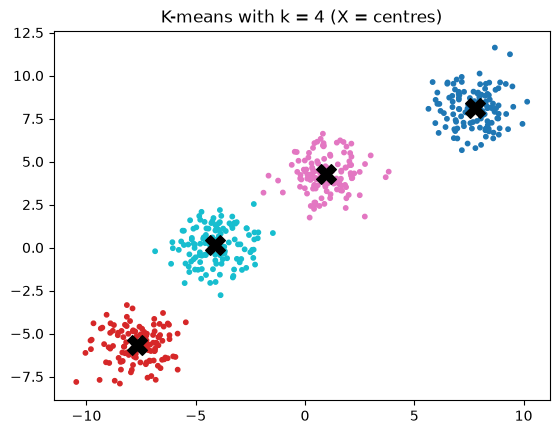

In [8]:
km = KMeans(n_clusters=4, n_init=10, random_state=0)
labels = km.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=10)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c="black", marker="X", s=200)
plt.title("K-means with k = 4 (X = centres)")
plt.show()

🧪 **Try it:** Make the groups overlap with `make_blobs(n_samples=500, centers=4, cluster_std=2.5, random_state=3)`.
Run `scores_for_k` again. Do the elbow and the silhouette still point to k = 4?

In [ ]:
# your code here

## 3. Can we trust the scores?
### K-means always finds groups, even in random noise

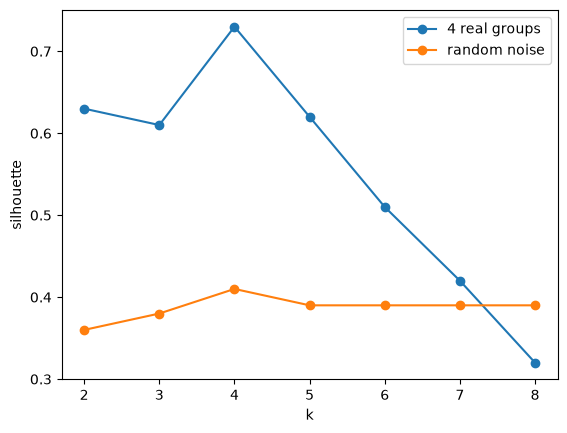

In [10]:
noise = np.random.default_rng(0).random((500, 2))      # completely random, no groups
scores_noise = scores_for_k(noise)

plt.plot(scores.index, scores["silhouette"], marker="o", label="4 real groups")
plt.plot(scores_noise.index, scores_noise["silhouette"], marker="o", label="random noise")
plt.xlabel("k")
plt.ylabel("silhouette")
plt.legend()
plt.show()

Real groups give a clear **peak**. Noise gives about 0.4 for every k: a score of 0.4 can come from nothing.

### A score can prefer the wrong answer

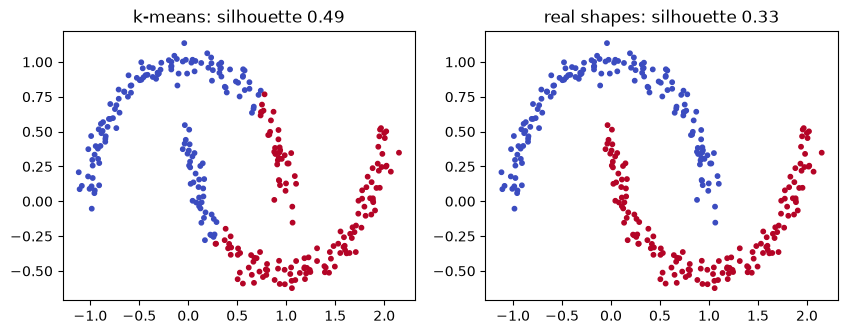

In [11]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.06, random_state=0)
labels_moons = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=labels_moons, cmap="coolwarm", s=10)
axes[0].set_title(f"k-means: silhouette {silhouette_score(X_moons, labels_moons):.2f}")
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap="coolwarm", s=10)
axes[1].set_title(f"real shapes: silhouette {silhouette_score(X_moons, y_moons):.2f}")
plt.show()

The wrong split scores **higher**. The silhouette likes round groups, just like k-means. Always look at the result.

## 4. The full workflow on real data: wine
1. Scale  2. Try several k  3. Look at the clusters  4. Describe them

In [12]:
scores_for_k(X_wine_s, ks=range(2, 7))     # X_wine_s is already scaled (section 1)

,inertia,silhouette
k,,
2,1659,0.27
3,1278,0.28
4,1181,0.25
5,1110,0.20
6,1044,0.20


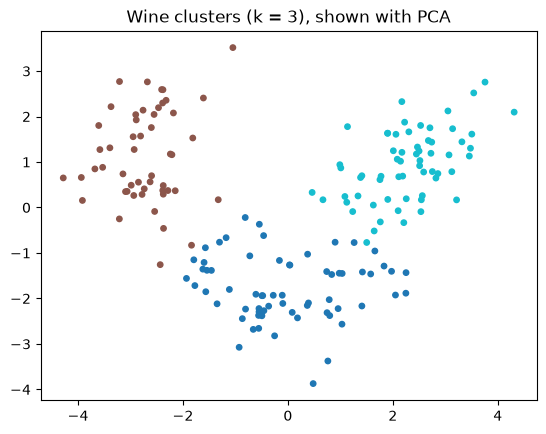

In [16]:
wine_labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_wine_s)

points = PCA(n_components=2).fit_transform(X_wine_s)     # 13D -> 2D, only for the plot
plt.scatter(points[:, 0], points[:, 1], c=wine_labels, cmap="tab10", s=15)
plt.title("Wine clusters (k = 3), shown with PCA")
plt.show()

In [17]:
# describe each cluster in the ORIGINAL units
features = ["alcohol", "malic_acid", "flavanoids", "color_intensity", "proline"]
profile = X_wine.groupby(wine_labels)[features].mean()
profile["n_wines"] = np.bincount(wine_labels)
profile.round(1)

,alcohol,malic_acid,flavanoids,color_intensity,proline,n_wines
0,12.3,1.9,2.0,3.0,510.2,65
1,13.1,3.3,0.8,7.2,619.1,51
2,13.7,2.0,3.0,5.5,1100.2,62


Can you give each cluster a short name, for example "strong, rich in proline"?

The dataset happens to include the real grape type, so we can peek at how well the clusters match it:

In [18]:
pd.crosstab(wine_labels, wine.target, rownames=["cluster"], colnames=["grape type"])

grape type,0,1,2
cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


🧪 **Try it:** Run the wine workflow **without scaling** (use `X_wine` instead of `X_wine_s`).
What happens to the silhouette, the cluster profiles and the match with the grape types?

In [19]:
# your code here

## Summary: four checks before you trust a clustering
1. Scale, then try several k
2. Elbow and silhouette: look for a clear bend and a clear peak
3. Look at the clusters (plot them, with PCA if there are many features)
4. Describe them in words: can you name and use each group?